# Experiment #10: Boosting Ensemble (AdaBoost) for Iris Flower Classification

**Dataset:** Iris (`iris.csv`) - 150 flowers, 4 measurements + species  
**Name:** Adithya Rajesh  |  **Class:** R3AI  |  **Roll No:** B25CTA07  |  **Date:** 13-10-2026

**Objective:** Implement a **boosting ensemble method** to classify the iris flower species. We preprocess the data, train an **AdaBoost** classifier that combines many weak learners (decision stumps), and evaluate its performance using **accuracy** and a **classification report**.

> **Note:** The notebook must stay in the same folder as `iris.csv`.


## Boosting - The Idea

**Boosting** is an ensemble technique that trains a sequence of **weak learners** (models only slightly better than random). Each new learner focuses on the samples that the previous learners got **wrong**, and every learner is given a **weight** based on how accurate it is. The final prediction is a weighted vote of all learners, which turns many weak models into one strong model.

**AdaBoost (Adaptive Boosting)** is the classic boosting algorithm. Its weak learner is usually a **decision stump** (a decision tree of depth 1).


## 1. Import the Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

## 2. Load the Iris Dataset

In [2]:
df = pd.read_csv('iris.csv')
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print('Species distribution:')
print(df['Species'].value_counts())

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 3. Data Preprocessing

- The `Id` column is just an identifier and is **dropped**.
- The four measurements are separated into the **input features** `X`.
- The `Species` text labels are converted into numeric values using **LabelEncoder**, since classifiers work with numbers.


In [4]:
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

X = df[features].to_numpy(dtype=float)

encoder = LabelEncoder()
y = encoder.fit_transform(df['Species'])

print('Features:', features)
print('Feature matrix shape:', X.shape)
print('Encoded classes:', list(enumerate(encoder.classes_)))

Features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Feature matrix shape: (150, 4)
Encoded classes: [(0, 'Iris-setosa'), (1, 'Iris-versicolor'), (2, 'Iris-virginica')]


## 4. Split into Training and Testing Sets

We use a 75% / 25% split with stratification so all three species are represented in both sets.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=16, stratify=y)

print('Training set:', X_train.shape)
print('Test set:    ', X_test.shape)

Training set: (112, 4)
Test set:     (38, 4)


## 5. Train the Boosting Ensemble (AdaBoost)

`AdaBoostClassifier` combines **50 decision stumps** (depth-1 trees). Each stump corrects the mistakes of the previous ones, and the stumps are combined into a strong classifier.


In [6]:
boost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=16)

boost.fit(X_train, y_train)
print('Boosting ensemble trained with', boost.n_estimators, 'weak learners')

Boosting ensemble trained with 50 weak learners


## 6. Predict the Test Samples and Evaluate

### Accuracy and Classification Report


In [7]:
y_pred = boost.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

Accuracy: 1.0

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        13
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        12

       accuracy                           1.00        38
      macro avg       1.00      1.00      1.00        38
   weighted avg       1.00      1.00      1.00        38



### Confusion Matrix

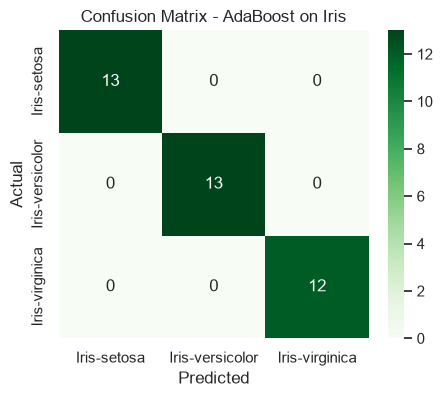

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.title('Confusion Matrix - AdaBoost on Iris')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 7. Effect of the Number of Weak Learners

Boosting improves as weak learners are added. Below we record the test accuracy as the number of stumps grows - a single stump is weak, but the ensemble quickly becomes strong.


Number of learners =   1  ->  Accuracy = 0.6579
Number of learners =   2  ->  Accuracy = 0.6842
Number of learners =   3  ->  Accuracy = 0.9737
Number of learners =   5  ->  Accuracy = 0.9737
Number of learners =  10  ->  Accuracy = 1.0000
Number of learners =  20  ->  Accuracy = 1.0000
Number of learners =  50  ->  Accuracy = 1.0000


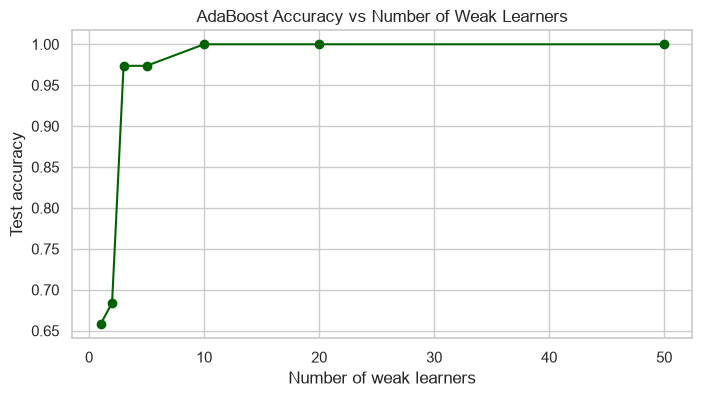

In [9]:
n_values = [1, 2, 3, 5, 10, 20, 50]
accuracies = []

for n in n_values:
    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=n,
        random_state=16)
    model.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, model.predict(X_test)))

for n, a in zip(n_values, accuracies):
    print(f'Number of learners = {n:>3}  ->  Accuracy = {a:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(n_values, accuracies, marker='o', color='darkgreen')
plt.title('AdaBoost Accuracy vs Number of Weak Learners')
plt.xlabel('Number of weak learners')
plt.ylabel('Test accuracy')
plt.grid(True)
plt.show()

---
## Inference & Analysis

- **Boosting** turned many simple **decision stumps** into a strong classifier. A single stump achieved only about **0.66** accuracy, but as more weak learners were added the accuracy quickly climbed and reached **1.00** by roughly 10 learners.
- With **50 weak learners**, the AdaBoost ensemble achieved **100% accuracy** on the test set - a perfect classification report (precision, recall and F1-score of **1.00** for all three species).
- The confusion matrix is perfectly diagonal, meaning every one of the 38 test flowers was classified into the correct species.
- This experiment shows the power of **ensemble learning**: instead of relying on one complex model, boosting combines many simple models, each fixing the errors of the previous ones.

---
**End of Experiment #10.**
